<a href="https://colab.research.google.com/github/apoorwa46/ML-Project/blob/main/PBL2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install hmmlearn

import warnings
warnings.filterwarnings("ignore")

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    silhouette_score
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    GradientBoostingRegressor, GradientBoostingClassifier,
    ExtraTreesRegressor, ExtraTreesClassifier
)
from sklearn.svm import SVR, SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from hmmlearn.hmm import GaussianHMM

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


In [3]:
uploaded = files.upload()  # Upload city_day.csv

file_name = next(iter(uploaded))
df_raw = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Uploaded file:", file_name)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())


Saving city_day.csv to city_day.csv
Uploaded file: city_day.csv
Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [6]:
#3. Problem identification and dataset familiarization

print("Rows and columns:", df_raw.shape)
print("\nColumns:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nStatistical summary:")
display(df_raw.describe(include="all").T)

print("\nMissing values (%):")
display((df_raw.isnull().mean() * 100).sort_values(ascending=False).round(2))

print("\nDuplicate rows:", df_raw.duplicated().sum())


Rows and columns: (29531, 16)

Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-nu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,29531,26,Ahmedabad,2009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,29531,2009,2020-06-26,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,24933.0,NaN,NaN,NaN,67.450578,64.661449,0.04,28.82,48.57,80.59,949.99
PM10,18391.0,NaN,NaN,NaN,118.127103,90.60511,0.01,56.255,95.68,149.745,1000.0
NO,25949.0,NaN,NaN,NaN,17.57473,22.785846,0.02,5.63,9.89,19.95,390.68
NO2,25946.0,NaN,NaN,NaN,28.560659,24.474746,0.01,11.75,21.69,37.62,362.21
NOx,25346.0,NaN,NaN,NaN,32.309123,31.646011,0.0,12.82,23.52,40.1275,467.63
NH3,19203.0,NaN,NaN,NaN,23.483476,25.684275,0.01,8.58,15.85,30.02,352.89
CO,27472.0,NaN,NaN,NaN,2.248598,6.962884,0.0,0.51,0.89,1.45,175.81
SO2,25677.0,NaN,NaN,NaN,14.531977,18.133775,0.01,5.67,9.16,15.22,193.86



Missing values (%):


,0
Xylene,61.32
PM10,37.72
NH3,34.97
Toluene,27.23
Benzene,19.04
AQI,15.85
AQI_Bucket,15.85
PM2.5,15.57
NOx,14.17
O3,13.62



Duplicate rows: 0


In [7]:
# . Data cleaning and feature preparation
df = df_raw.copy()

# Parse date and remove exact duplicate records
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.drop_duplicates()
df = df.dropna(subset=["Date"])

# Extract calendar features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfYear"] = df["Date"].dt.dayofyear

pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]
pollutants = [c for c in pollutants if c in df.columns]

print("Cleaned dataset shape:", df.shape)
print("Cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Pollutant features:", pollutants)


Cleaned dataset shape: (29531, 20)
Cities: 26
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Pollutant features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']


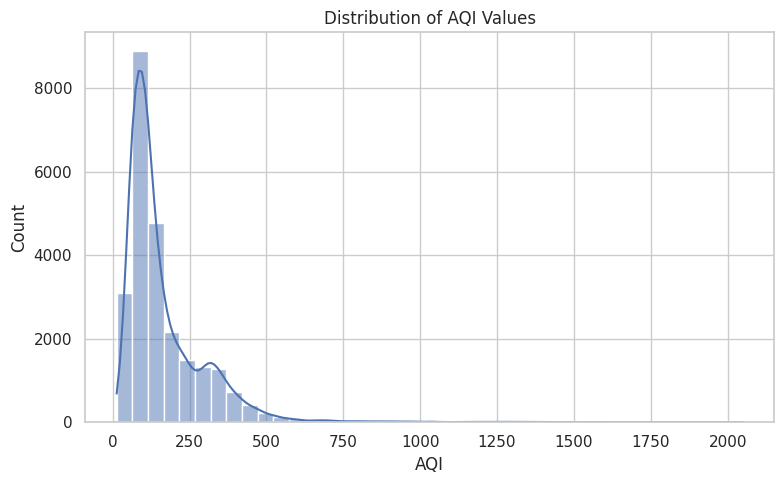

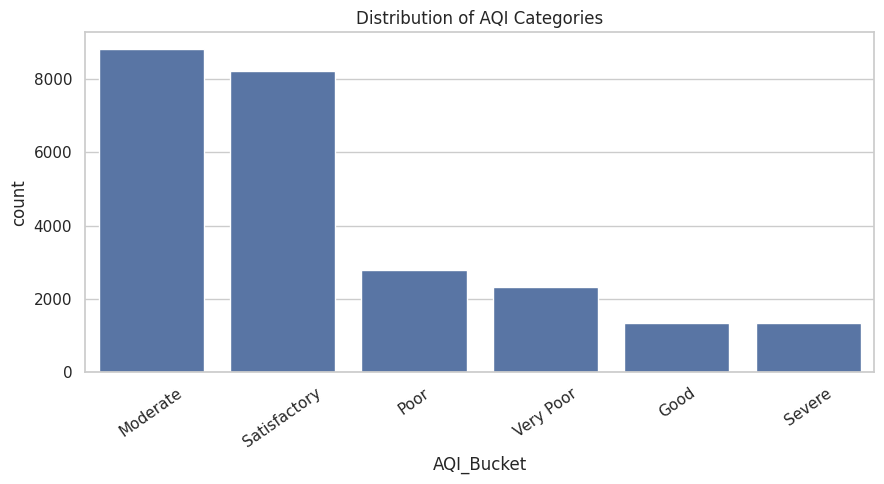

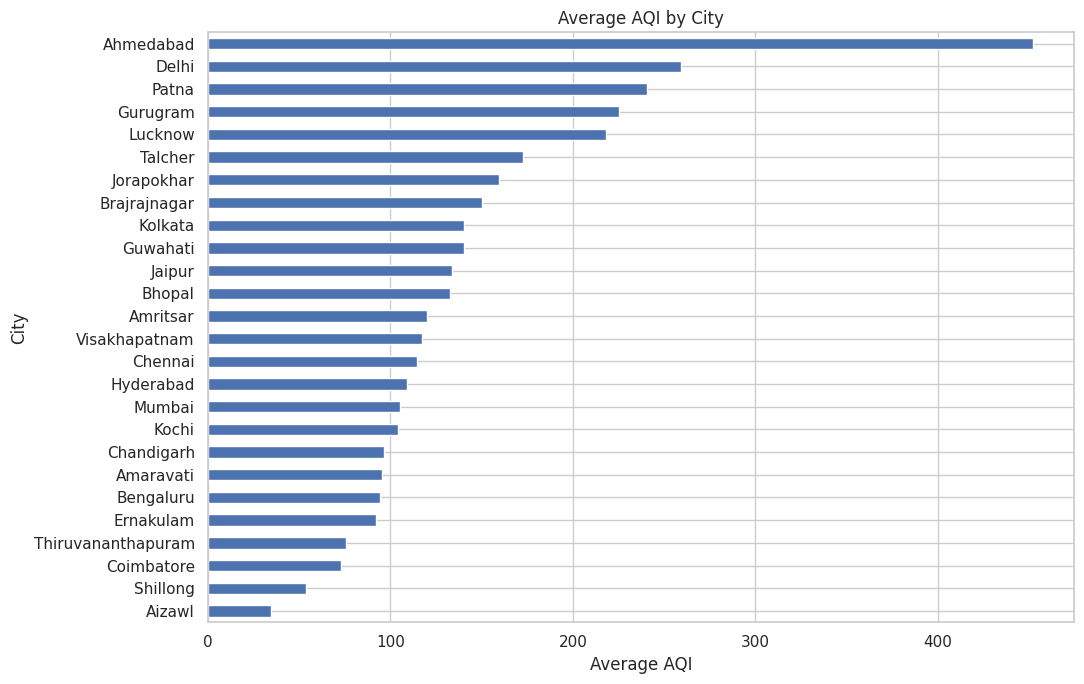

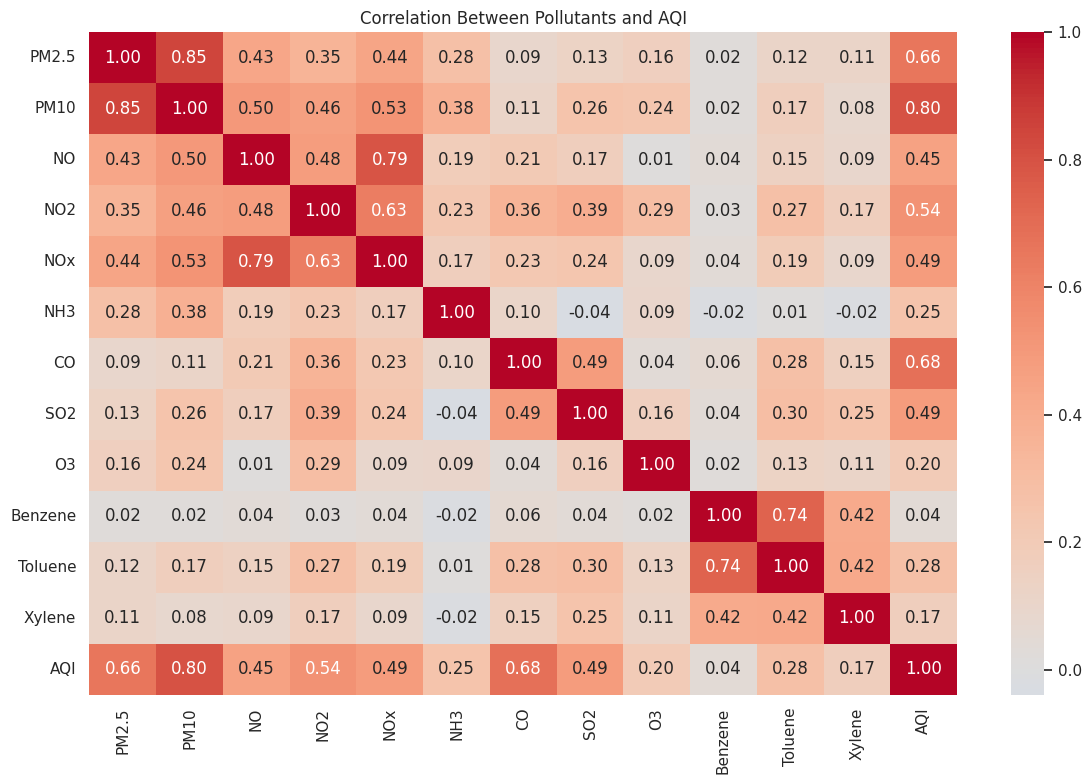

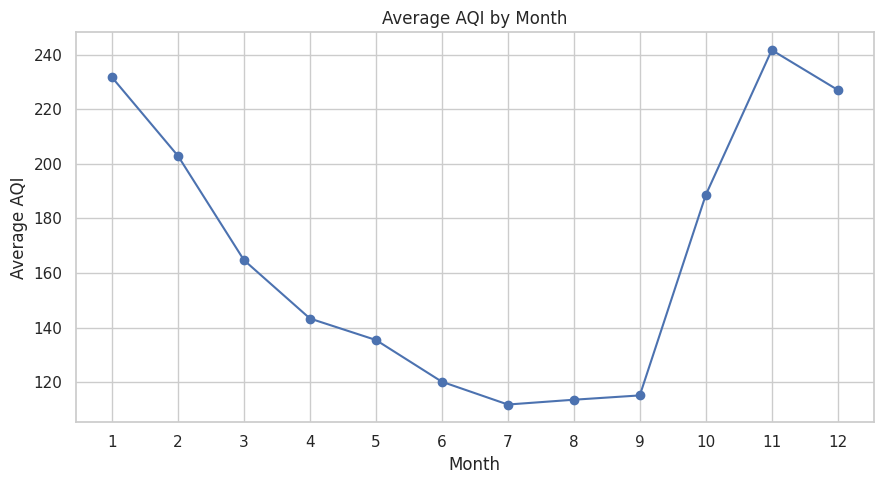

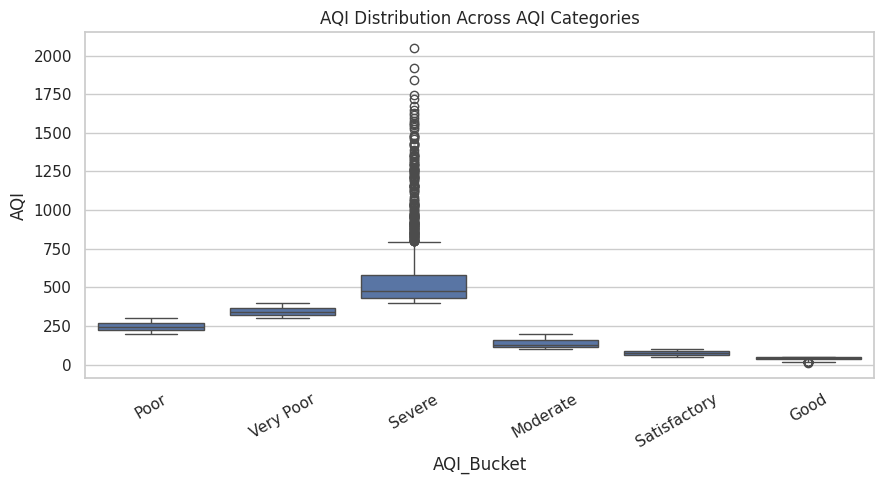

In [8]:
#5. Exploratory Data Analysis (EDA) — required graphs
# Graph 1: AQI distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["AQI"].dropna(), bins=40, kde=True)
plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.tight_layout()
plt.show()

# Graph 2: AQI category distribution
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="AQI_Bucket",
              order=df["AQI_Bucket"].value_counts().index)
plt.title("Distribution of AQI Categories")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# Graph 3: Average AQI by city
city_aqi = df.groupby("City")["AQI"].mean().dropna().sort_values()
plt.figure(figsize=(11, 7))
city_aqi.plot(kind="barh")
plt.title("Average AQI by City")
plt.xlabel("Average AQI")
plt.tight_layout()
plt.show()

# Graph 4: Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df[pollutants + ["AQI"]].corr(), cmap="coolwarm",
            center=0, annot=True, fmt=".2f")
plt.title("Correlation Between Pollutants and AQI")
plt.tight_layout()
plt.show()

# Graph 5: Monthly AQI trend
monthly_aqi = df.dropna(subset=["AQI"]).groupby("Month")["AQI"].mean()
plt.figure(figsize=(9, 5))
monthly_aqi.plot(marker="o")
plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# Graph 6: AQI by category
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="AQI_Bucket", y="AQI",
            order=df["AQI_Bucket"].dropna().unique())
plt.title("AQI Distribution Across AQI Categories")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


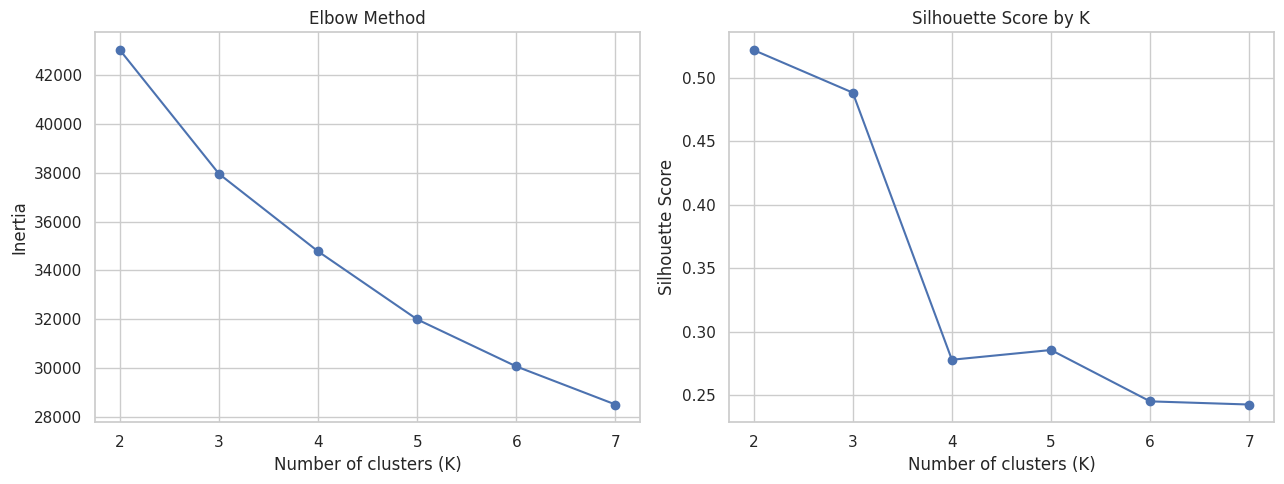

Selected K based on highest sample silhouette score: 2
Full-data silhouette score: 0.5137


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
Cluster,,,,,,,,,,,,,
0,53.38,96.07,11.53,21.95,23.61,21.55,1.21,11.37,32.66,2.12,5.12,2.05,129.83
1,139.89,248.61,49.62,63.92,78.01,37.38,8.15,31.25,44.38,9.09,25.58,6.80,358.39


In [9]:
#PBL 2 — K-Means clustering of pollutant profiles
# Clustering is unsupervised: AQI and AQI_Bucket are NOT used to form clusters.
cluster_data = df[pollutants].copy()

cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()

cluster_imputed = cluster_imputer.fit_transform(cluster_data)
cluster_scaled = cluster_scaler.fit_transform(cluster_imputed)

# Sample for faster silhouette calculation on larger datasets
rng = np.random.RandomState(RANDOM_STATE)
sample_size = min(5000, len(cluster_scaled))
sample_idx = rng.choice(len(cluster_scaled), sample_size, replace=False)
cluster_sample = cluster_scaled[sample_idx]

k_values = range(2, 8)
inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_sample = km.fit_predict(cluster_sample)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(cluster_sample, labels_sample))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(silhouette_scores))]
print("Selected K based on highest sample silhouette score:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans.fit_predict(cluster_scaled)

print("Full-data silhouette score:",
      round(silhouette_score(cluster_sample,
          kmeans.predict(cluster_sample)), 4))

display(df.groupby("Cluster")[pollutants + ["AQI"]].mean().round(2))


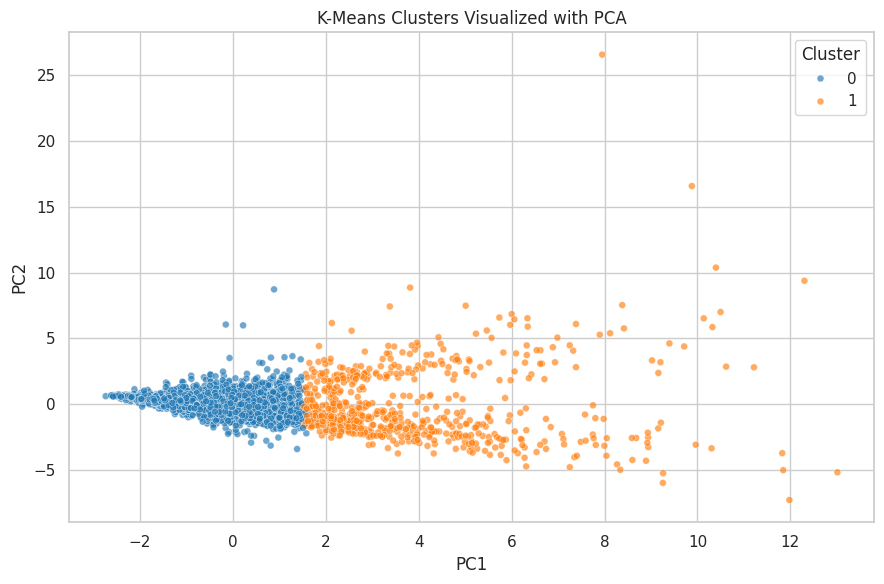

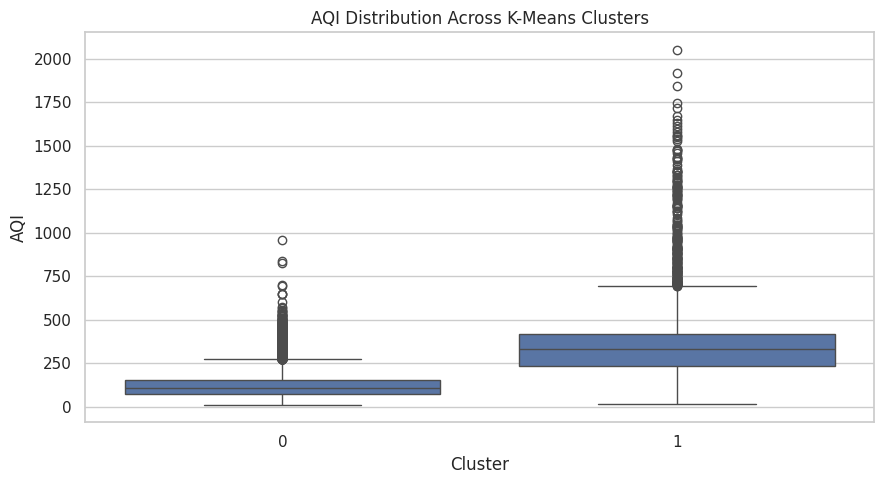

In [10]:
#K-Means cluster visualization using PCA
# Reduce pollutant feature space to two dimensions for visualization only
pca = PCA(n_components=2, random_state=RANDOM_STATE)
cluster_2d = pca.fit_transform(cluster_scaled)

plot_clusters = pd.DataFrame({
    "PC1": cluster_2d[:, 0],
    "PC2": cluster_2d[:, 1],
    "Cluster": df["Cluster"].astype(str).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_clusters.sample(min(5000, len(plot_clusters)),
                              random_state=RANDOM_STATE),
    x="PC1", y="PC2", hue="Cluster", palette="tab10",
    alpha=0.65, s=25
)
plt.title("K-Means Clusters Visualized with PCA")
plt.tight_layout()
plt.show()

# Compare clusters with AQI after clustering (AQI was not used to create clusters)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Cluster", y="AQI")
plt.title("AQI Distribution Across K-Means Clusters")
plt.tight_layout()
plt.show()


In [11]:
#Hidden Markov Model (Gaussian HMM)
# HMM objective:
# Model daily AQI observations as emissions from hidden air-quality regimes.
# We fit sequences city-by-city in chronological order. Sequence lengths prevent
# the HMM from learning a transition from the last day of one city to another.

from hmmlearn.hmm import GaussianHMM

hmm_data = df.dropna(subset=["AQI", "City", "Date"]).copy()
hmm_data = hmm_data.sort_values(["City", "Date"])

# Use a chronological 80/20 split within each city
train_sequences = []
test_sequences = []
train_lengths = []
test_lengths = []
test_city_frames = []

for city, group in hmm_data.groupby("City"):
    values = group["AQI"].astype(float).values.reshape(-1, 1)
    if len(values) < 20:
        continue

    split_point = int(len(values) * 0.8)
    if split_point < 10 or len(values) - split_point < 2:
        continue

    train_sequences.append(values[:split_point])
    test_sequences.append(values[split_point:])
    train_lengths.append(split_point)
    test_lengths.append(len(values) - split_point)

    test_part = group.iloc[split_point:].copy()
    test_city_frames.append(test_part)

if len(train_sequences) == 0:
    raise ValueError("Not enough per-city AQI observations to train the HMM.")

X_hmm_train = np.vstack(train_sequences)
X_hmm_test = np.vstack(test_sequences)

print("HMM training observations:", len(X_hmm_train))
print("HMM testing observations:", len(X_hmm_test))
print("City sequences used:", len(train_sequences))

# Three hidden regimes are a starting assumption; compare 2-5 states if time permits.
N_HIDDEN_STATES = 3

hmm_model = GaussianHMM(
    n_components=N_HIDDEN_STATES,
    covariance_type="diag",
    n_iter=200,
    random_state=RANDOM_STATE
)
hmm_model.fit(X_hmm_train, lengths=train_lengths)

test_log_likelihood = hmm_model.score(X_hmm_test, lengths=test_lengths)
print("HMM test log-likelihood:", round(test_log_likelihood, 2))
print("HMM test log-likelihood per observation:",
      round(test_log_likelihood / len(X_hmm_test), 4))

print("\nHidden-state transition probability matrix:")
display(pd.DataFrame(
    hmm_model.transmat_,
    index=[f"From state {i}" for i in range(N_HIDDEN_STATES)],
    columns=[f"To state {i}" for i in range(N_HIDDEN_STATES)]
).round(3))


HMM training observations: 19871
HMM testing observations: 4979
City sequences used: 26
HMM test log-likelihood: -25389.08
HMM test log-likelihood per observation: -5.0992

Hidden-state transition probability matrix:


,To state 0,To state 1,To state 2
From state 0,0.928,0.027,0.045
From state 1,0.034,0.963,0.003
From state 2,0.041,0.001,0.958


,count,mean,median,std
Hidden_State,,,,
2,10463,76.43,76.0,22.44
0,8292,144.62,137.0,38.55
1,6095,350.74,321.0,171.18


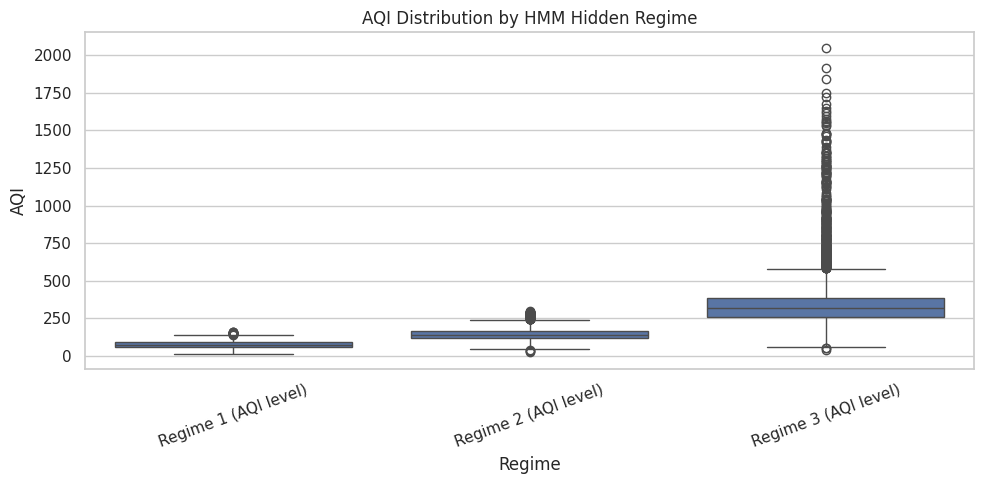

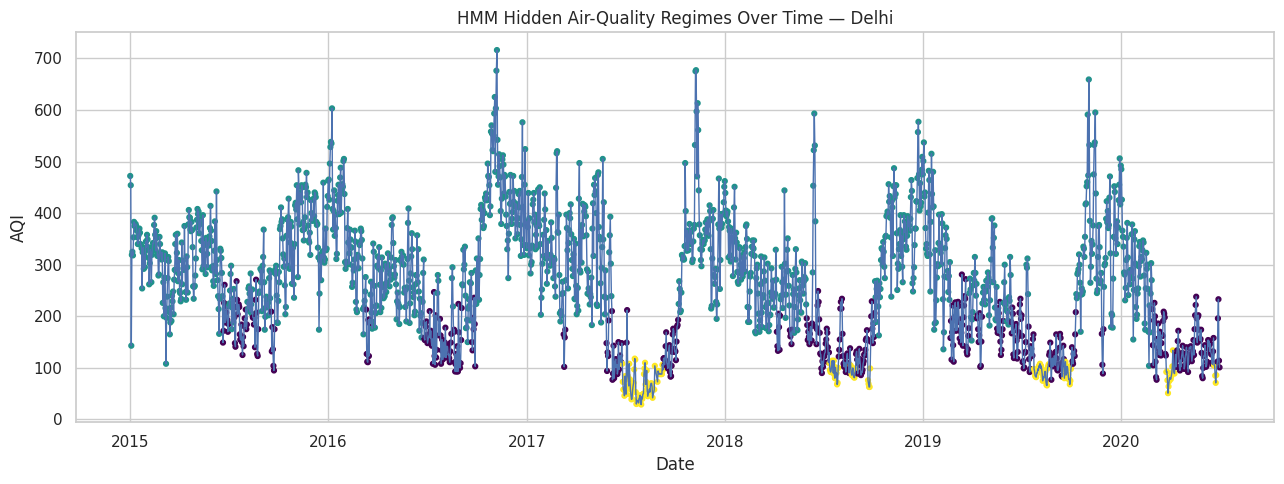

Example city: Delhi


In [12]:
#HMM hidden-state interpretation and visualization
# Decode hidden states for each city independently to avoid transitions across cities.
decoded_frames = []

for city, group in hmm_data.groupby("City"):
    group = group.sort_values("Date").copy()
    if len(group) < 2:
        continue
    obs = group["AQI"].astype(float).values.reshape(-1, 1)
    group["Hidden_State"] = hmm_model.predict(obs)
    decoded_frames.append(group)

hmm_decoded = pd.concat(decoded_frames, ignore_index=True)

# Interpret each hidden state using its mean observed AQI.
state_summary = (
    hmm_decoded.groupby("Hidden_State")["AQI"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean")
)
display(state_summary.round(2))

# Label states by their mean AQI (low to high); these are data-driven descriptions.
ordered_states = state_summary.index.tolist()
state_labels = {
    state: f"Regime {rank + 1} (AQI level)"
    for rank, state in enumerate(ordered_states)
}
hmm_decoded["Regime"] = hmm_decoded["Hidden_State"].map(state_labels)

plt.figure(figsize=(10, 5))
sns.boxplot(data=hmm_decoded, x="Regime", y="AQI",
            order=[state_labels[s] for s in ordered_states])
plt.title("AQI Distribution by HMM Hidden Regime")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Example: hidden regimes over time for the city with most observations
example_city = hmm_decoded["City"].value_counts().idxmax()
example = hmm_decoded[hmm_decoded["City"] == example_city].sort_values("Date")

plt.figure(figsize=(13, 5))
plt.plot(example["Date"], example["AQI"], linewidth=1, label="Observed AQI")
plt.scatter(example["Date"], example["AQI"],
            c=example["Hidden_State"], cmap="viridis", s=12,
            label="HMM hidden regime")
plt.title(f"HMM Hidden Air-Quality Regimes Over Time — {example_city}")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

print("Example city:", example_city)


In [15]:
#Comparative performance analysis

# Clustering metric: silhouette score (higher is generally better; range -1 to 1)
cluster_metric = silhouette_scores[int(best_k) - 2]
print(f"K-Means selected K={best_k}; sample silhouette={cluster_metric:.4f}")

# HMM metric: held-out log-likelihood per observation (higher is better
# when comparing HMM configurations evaluated on the same test sequences).
print("HMM test log-likelihood per observation:",
      round(test_log_likelihood / len(X_hmm_test), 4))

print("\n========== PROJECT RESULT SUMMARY ==========")
print("K-Means clusters:", best_k)
print("K-Means silhouette:", round(cluster_metric, 4))
print("HMM hidden states:", N_HIDDEN_STATES)
print("HMM test log-likelihood / observation:",
      round(test_log_likelihood / len(X_hmm_test), 4))


K-Means selected K=2; sample silhouette=0.5217
HMM test log-likelihood per observation: -5.0992

========== PROJECT RESULT SUMMARY ==========
K-Means clusters: 2
K-Means silhouette: 0.5217
HMM hidden states: 3
HMM test log-likelihood / observation: -5.0992


In [16]:
print("""PROJECT INTERPRETATION GUIDE

3. K-Means clustering:
   K-Means groups days with similar pollutant profiles without using AQI
   or AQI_Bucket to form the groups. Use the elbow curve and silhouette
   score to justify K. Afterwards, compare average AQI by cluster to
   interpret the discovered pollutant profiles.

4. Hidden Markov Model:
   The Gaussian HMM represents daily AQI values as observations generated
   by hidden air-quality regimes. The transition matrix describes the
   probability of moving between regimes. State-wise mean AQI helps label
   the regimes from lower to higher AQI levels. Test log-likelihood
   measures how well the held-out sequence is explained by the fitted HMM.

""")


PROJECT INTERPRETATION GUIDE

3. K-Means clustering:
   K-Means groups days with similar pollutant profiles without using AQI
   or AQI_Bucket to form the groups. Use the elbow curve and silhouette
   score to justify K. Afterwards, compare average AQI by cluster to
   interpret the discovered pollutant profiles.

4. Hidden Markov Model:
   The Gaussian HMM represents daily AQI values as observations generated
   by hidden air-quality regimes. The transition matrix describes the
   probability of moving between regimes. State-wise mean AQI helps label
   the regimes from lower to higher AQI levels. Test log-likelihood
   measures how well the held-out sequence is explained by the fitted HMM.


